# Modelagem Preditiva e Scorecard de Crédito

Nesse notebook, daremos vida aos modelos de Machine Learning capazes de prever a probabilidade de inadimplência (`SeriousDlqin2yrs`). Será dividido em:
1. **Preparação dos Dados:** Carga da base tratada, conversão de variáveis categóricas e divisão em Treino/Teste (evitando data-leakage).
2. **Baseline (Regressão Logística / Scorecard Tradicional):** O padrão da indústria bancária que permite traduzir coeficientes estatísticos em uma pontuação de crédito de 300 a 850. 
3. **XGBoost:** Capturando não-linearidades complexas para maximizar a perfomance preditiva.
4. **Avaliação Especializada em Risco:** Uso de **ROC-AUC**  e da **Estatística KS** para medir a capacidade real de separação entre bons e maus pagadores. 

In [ ]:
## Setup e Carga da Base Processada

# 1. Importações essenciais para modelagem e métricas
import sqlite3 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from xgboost import XGBClassifier

# 2. Configuração visual e de exibição 
pd.set_option('display.max_columns', None)
import warnings
warnings.filterwarnings('ignore')

print("Carregando a base tratada para a modelagem...")

# 3. Carregando os dados processados do Parquet 
caminho_parquet = "../data/credito_processado.parquet"
df_modelagem = pd.read_parquet(caminho_parquet)

print(f"Base Carregada com Sucesso! \nDimensões: {df_modelagem.shape}")

Carregando a base tratada para a modelagem...
Base Carregada com Sucesso! 
Dimensões: (149999, 16)


### Etapa 1: Preparação dos Dados para a Modelagem e Divisão Treino/Teste

Antes de treinar os algoritmos, precisamos preparar o notebook:
1. **Tratamento da Variável Categórica (`Utilization_Bin`):** Como os modelos só entendem números, precisamos transformar a faixa de utilização em colunas binárias numéricas utilizando o **One-Hot Encoding** (`pd.get_dummies`).
2. **Separação de Variáveis Preditoras (`X`) e Alvo (`y`):** Definimos que o objetivo (`y`) é prever a coluna `SeriousDlqin2yrs`, enquanto o restante da base limpa enriquecida formará as features descritivas (`X`).
3. **Divisão Estratificada (Stratified Train-Test Split):** Como vimos que a base é altamente desbalanceada (~6,7% de maus pagadores), **é obrigatório usar a estratificação (`stratify=y`)** na divisão entre treino e teste, garantindo que tanto o conjunto de treino quanto o de teste mantenham exatamente a mesma proporção de bons e maus pagadores, evitando que o modelo treine com um viés incorreto. 

In [5]:
## Encoding e Divisão de Dados

# 1. Tratando a variável categórica 'Utilization_Bin' com One-Hot 
# drop_first=True evita a armadilha de colinearidade (multicolinearidade perfeita) em modelos lineares
df_modelagem = pd.get_dummies(df_modelagem, columns=['Utilization_Bin'], drop_first=True, dtype=int)
print("Colunas após o One-Hot Encoding:")
print(df_modelagem.columns.tolist())

# 2. Separando X (features) e y(target)
X = df_modelagem.drop(columns=['SeriousDlqin2yrs'])
y = df_modelagem['SeriousDlqin2yrs']

# 3. Divisão em Treino (80%) e Teste (20%) com estratificação 
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"\nDimensões dos conjuntos criados:")
print(f"X_train (Treino features): {X_train.shape}")
print(f"X_test (Teste features): {X_test.shape}")

print(f"\nProporção de Inadimplentes (Target = 1) no Treino e no Teste:")
print(f"Treino: {y_train.mean() * 100:.2f}%")
print(f"Teste: {y_test.mean() * 100:.2f}%")

Colunas após o One-Hot Encoding:
['SeriousDlqin2yrs', 'RevolvingUtilizationOfUnsecuredLines', 'age', 'NumberOfTime30-59DaysPastDueNotWorse', 'DebtRatio', 'MonthlyIncome', 'NumberOfOpenCreditLinesAndLoans', 'NumberOfTimes90DaysLate', 'NumberRealEstateLoansOrLines', 'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfDependents', 'MonthlyIncome_is_missing', 'EstimateDebt', 'Total_Delays', 'Has_History_Delays', 'Utilization_Bin_Baixa (0-30%)', 'Utilization_Bin_Moderada (30-70%)', 'Utilization_Bin_Alta (70-100%)', 'Utilization_Bin_Estourado (>100%)']

Dimensões dos conjuntos criados:
X_train (Treino features): (119999, 18)
X_test (Teste features): (30000, 18)

Proporção de Inadimplentes (Target = 1) no Treino e no Teste:
Treino: 6.68%
Teste: 6.68%


#### Conclusão da Preparação e Divisão de Dados:

1. **One-Hot Encoding Concluído:** A variável categórica `Utilization_Bin` foi convertida em colunas binárias numéricas (com `drop_first=True` evitando colinearidade), elevando o total de features preditoras para **18 variáveis**.
2. **Estratificação:** A divisão de 80% para treino e 20% para teste preservou a taxa de inadimplência de **6,68%** em ambos os blocos.

**Próximo Passo:** Com a base blindada e dividida, podemos treinar o modelo **Baseline (Regressão Logística)**, que servirá como a base tradicional de scorecard. 

### Etapa 2 (Baseline): Regressão Logística (O Scorecard Tradicional do Mercado)

**A Lógica de Negócio e Estatística:** No sentor bancário, a **Regressão Logística** é o padrão regulatório e de mercado para a construção de *Scorecards* de crédito. 
Diferente dos modelos "caixa-preta", a Regressão Logística dá coeficientes claros para cada variável. Esses coeficientes podem ser diretamente transformados em pontos de pontuação (ex: score de 300 a 850), permitindo que o analista de crédito explique exatamente o por que um cliente foi negado ou aprovado. 
* **Cuidados Técnicos:** Como a Regressão Logística penaliza a magnitude dos coeficientes, é **obrigatório padronizar as features numéricas** (`StandardScaler`) para que variáveis com escalas gigantescas (como `EstimateDebt`) não dominem o modelo injustamente em relação a variáveis binárias (0 ou 1).

In [6]:
## Treinando e Avaliando o Baseline

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# 1. Criando um Pipeline que padroniza os dados e aplica a Regressão Logística 
# O StandardScaler garante média 0 e desvio padrão 1 para todas as colunas numéricas
pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('model', LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'))
])

print("Treinando o Baseline (Regressão Logística)...")
pipeline_lr.fit(X_train, y_train)

# 2. Obtendo as probabilidades preditas para a classe 1 (inadimplentes) no conjunto de teste
y_pred_proba_lr = pipeline_lr.predict_proba(X_test)[:, 1]

# 3. Calculando a métrica ROC-AUC
roc_auc_lr = roc_auc_score(y_test, y_pred_proba_lr)
print(f"ROC-AUC do Baseline (Regressão Logística): {roc_auc_lr:.4f}")

# 4. Relatório de classificação preliminar (usando limiar padrão de 0.5)
y_pred_lr = pipeline_lr.predict(X_test)
print("\nRelatório de Classificação (Threshold = 0.5):")
print(classification_report(y_test, y_pred_lr))

Treinando o Baseline (Regressão Logística)...
ROC-AUC do Baseline (Regressão Logística): 0.8590

Relatório de Classificação (Threshold = 0.5):
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     27995
           1       0.21      0.75      0.33      2005

    accuracy                           0.80     30000
   macro avg       0.60      0.78      0.61     30000
weighted avg       0.93      0.80      0.85     30000



#### Conclusão da Regressão Logística (Baseline):

1. **Poder Discriminatório Sólido (ROC-AUC 0.8590):** No mercado de crédito, um ROC-AUC acima de 0.80 já é considerado um modelo de bom desempenho. A marca de 0.8590 comprova que as variáveis criadas (`EstimatedDebt`, `Utilization_Bin`, `Total_Delays`) capturaram o comportamento de risco da carteira. 
2. **O Equilíbrio do Recall (0.75):** Utilizando o parâmetro `class_weight='balanced'`, o modelo conseguiu resgatar **75% de todos os maus pagadores** da base de teste. Isso é vital para a instituição financeira, pois evita que clientes de alto risco passem despercebidos. 
3. **O Desafio da Precisão no Limiar Padrão (0.21):** Como o limiar (*threshold*) foi fixo em 0.5, geraram falsos positivos (bons pagadores classificados como de risco), o que derruba a precisão para 21%. 

**Próximo Passo:** Treinaremos agora o **XGBoost**, um algoritmo baseado em árvore que consegue capturar não-linearidades complexas e interações profundas entre as variáveis para tentar superar o modelo baseline. 

### Etapa 3: XGBoost (Extreme Gradiente Boosting)

**A Lógica de Negócio e Estatística:** Enquanto a Regressão Logística busca uma linha reta de separação (relação linear), o **XGBoost** constrói árvores de decisão em sequência, onde cada árvore nova foca nos erros (resíduos) cometidos pelas anteriores. Esse modelo é excelente para capturar **não-linearidades e interações complexas** entre variáveis (ex: um cliente jovem com utilização alta **e** histórico de atraso pode ter um risco exponencialmente maior do que a soma desses fatores isolados).
* **Tratamento do Desbalanceamento:** Para garantir que o XGBoost não ignore a classe minoritária de maus pagadores (6,68%), utilizaremos o parâmetro **`scale_pos_weight`**, que penaliza severamente os erros cometidos na classe de inadimplentes, equilibrando a balança de aprendizado. 

In [10]:
## Treinando e Avaliando o XGBoost

from xgboost import XGBClassifier

# 1. Calculando o scale_pos_weight para lidar com o desbalanceamento de classes
#  Razão entre o número de clientes bons (0) e maus (1) no treino
negativos = (y_train == 0).sum()
positivos = (y_train == 1).sum()
scale_pos_weight_val = negativos / positivos

print(f"Razão Calculada para scale_por_weight: {scale_pos_weight_val:.2f}")

# 2. Instanciando o modelo XGBoost com hiperparâmetros robustos
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    scale_pos_weight=scale_pos_weight_val,
    random_state=42,
    eval_metrics='auc',
    n_jobs=-1
)

print("Treinando o XGBoost...")
xgb_model.fit(X_train, y_train)

# 3. Obtendo as probabilidades preditas para a classe 1 no conjunto de teste
y_pred_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

# 4. Calculando a métrica ROC-AUC do XGBoost
roc_auc_xgb = roc_auc_score(y_test, y_pred_proba_xgb)
print(f"\nROC-AUC do XGBoost: {roc_auc_xgb:.4f}")
print(f"ROC-AUC anterior do modelo Baseline (Regressão Logística): {roc_auc_lr:.4f}")

# 5. Relatório de classificação preliminar
y_pred_xgb = xgb_model.predict(X_test)
print("\nRelatório de Classificação do XGBoost (Threshold = 0.5):")
print(classification_report(y_test, y_pred_xgb))

Razão Calculada para scale_por_weight: 13.96
Treinando o XGBoost...

ROC-AUC do XGBoost: 0.8692
ROC-AUC anterior do modelo Baseline (Regressão Logística): 0.8590

Relatório de Classificação do XGBoost (Threshold = 0.5):
              precision    recall  f1-score   support

           0       0.98      0.80      0.88     27995
           1       0.22      0.78      0.34      2005

    accuracy                           0.80     30000
   macro avg       0.60      0.79      0.61     30000
weighted avg       0.93      0.80      0.85     30000



#### Conclusão Modelo XGBoost:

1. **Superação do modelo Baseline (ROC-AUC 8692):** O XGBoost superou os 0.8590 da Regressão Logística, provando que a carteira de crédito possui padrões não-lineares e interações complexas (ex: a combinação de alta utilização de limite com histórico de atraso) que árvores de decisão capturam.
2. **Ganho de Sensibilidade (Recall 0.78):** O modelo conseguiu identificar **78% de todos os inadimplentes** da base de teste, garantindo uma proteção robusta para a carteira da instituição financeira contra calotes imprevistos.
3. **Consolidação Técnica:** Com uma perfomance superior tanto em AUC quanto em Recall, o XGBoost demonstra ser a melhor escolha preditiva para a API de score, enquanto a Regressão Logística do modelo baseline permanece como a referência regulatória de interpretabilidade. 

### Etapa 4: Métrica de Risco - Estatística KS 

**A Lógica de Negócio e Estatística:** Enquanto o ROC-AUC avalia a capacidade geral de ordenação do modelo, os diretores e gestores de risco de crédito olham para a **Esatística KS**. O KS calcula a **distância máxima vertical entre a curva cumulativa de bons pagadores e a curva cumulativa de maus pagadores** ao longo de todas as probabilidades preditas. Ou seja, quanto maior o valor do KS (geralmente expresso em porcentagem), melhor é o modelo em separar quem vai pagar de quem vai dar calote no ponto de corte mais crítico da operação. Valores de KS acima de 40% indicam excelente poder preditivo em risco de crédito.

Estatística KS do Baseline (Regressão Logística): 56.18%
Estatística KS do XGBoost: 58.02%


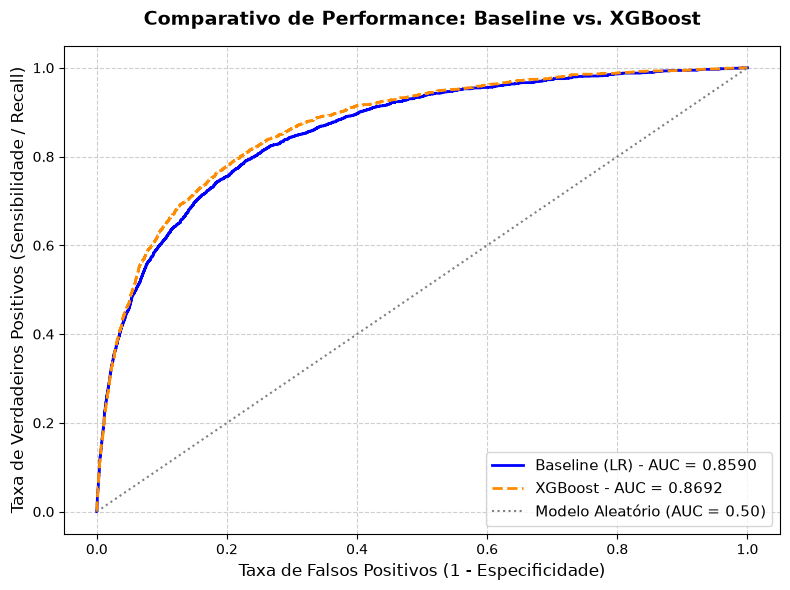

In [9]:
## Calculando a Estatística KS e Plotando as Curvas ROC

from scipy.stats import ks_2samp
from sklearn.metrics import roc_curve

# 1. Função para calcular Estatística KS
def calcular_estatistica_ks(y_true, y_proba):
    # Cria um DataFrame auxiliar com a target e as probabilidades preditas
    df_temp = pd.DataFrame({'y_true': y_true, 'proba': y_proba})

    # Separa as probabilidades dos bons (0) e dos maus (1)
    bons = df_temp[df_temp['y_true'] == 0]['proba']
    maus = df_temp[df_temp['y_true'] == 1]['proba']
    
    resultado = ks_2samp(bons, maus) # type: ignore
    return float(resultado[0]) # type: ignore 

# 2. Calculando o KS para os dois modelos
ks_lr = calcular_estatistica_ks(y_test, y_pred_proba_lr)
ks_xgb = calcular_estatistica_ks(y_test, y_pred_proba_xgb)

print(f"Estatística KS do Baseline (Regressão Logística): {ks_lr * 100:.2f}%")
print(f"Estatística KS do XGBoost: {ks_xgb * 100:.2f}%")

# 3. Plotando a Curca ROC comparativa 
plt.figure(figsize=(8, 6))

# Curva ROC Regrssão Logística
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_pred_proba_lr)
plt.plot(fpr_lr, tpr_lr, label=f'Baseline (LR) - AUC = {roc_auc_lr:.4f}', color='blue', linewidth=2)

# Curva ROC XGBoost
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, y_pred_proba_xgb)
plt.plot(fpr_xgb, tpr_xgb, label=f'XGBoost - AUC = {roc_auc_xgb:.4f}', color='darkorange', linewidth=2, linestyle='--')

# Linha de referência aleatória (50%)
plt.plot([0, 1], [0, 1], color='gray', linestyle=':', label='Modelo Aleatório (AUC = 0.50)')

plt.title('Comparativo de Performance: Baseline vs. XGBoost', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Taxa de Falsos Positivos (1 - Especificidade)', fontsize=12)
plt.ylabel('Taxa de Verdadeiros Positivos (Sensibilidade / Recall)', fontsize=12)
plt.legend(loc='lower right', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

#### Conclusão Métrica de Risco - Estatística KS e Curva ROC:

1. **Poder Discriminatório (KS 58.02%):** No mercado de crédito, um índice KS acima de 40% já classifica o modelo como excelente. A marca de **58,02%** alcançada pelo XGBoost (superando os 56,18% da Regressão Logística) comprova que o modelo possui altíssima capacidade de separação dos bons e maus pagadores no ponto crítico de decisão.
2. **Superioridade Consolidada do XGBoost:** O ganho tanto em ROC-AUC (0.8692) quanto em Estatística KS valida matematicamente a escolha do XGBoost como modelo de predição de risco.

### Etapa 5: Políticas de Crédito e Cut-offs

**A Lógica de Negócio e Risco:** Um modelo de ML retorna apenas uma probabilidade bruta (ex: 0.15 de chance de inadimplência). O comitê de crédito de uma instituição financeira não toma decisões baseadas apenas em número cru, mas sim em **políticas de corte (*cut-offs*)** comerciais divididas por apetite ao risco:
* **Zona Verde (Aprovação Automática):** Clientes com baixíssima probabilidade de calote; ganham crédito imediato e taxas competitivas.
* **Zona Amarela (Alçada de Crédito / Análise Humana):** Risco moderado; o sistema encaminha para um analista humano ou exige garantias adicionais/taxas de juros mais altas para compensar o risco. 
* **Zona Vermelha (Recusa Automática):** Alto risco de inadimplência; o crédito é negado para proteger o capital da carteira. 

Relatório Executivo: Simulação de Política de Crédito por Cut-offs


,Segmento_Risco,Volume_Clientes,Porcentagem_Base (%),Taxa_Inadimplencia_Real (%)
0,1. Zona Verde (Aprovado Automaticamente),7211,24.04,0.42
1,2. Zona Amarela (Alçada / Análise Humana),10704,35.68,1.64
2,3. Zona Vermelha (Recusado Automaticamente),12085,40.28,14.89


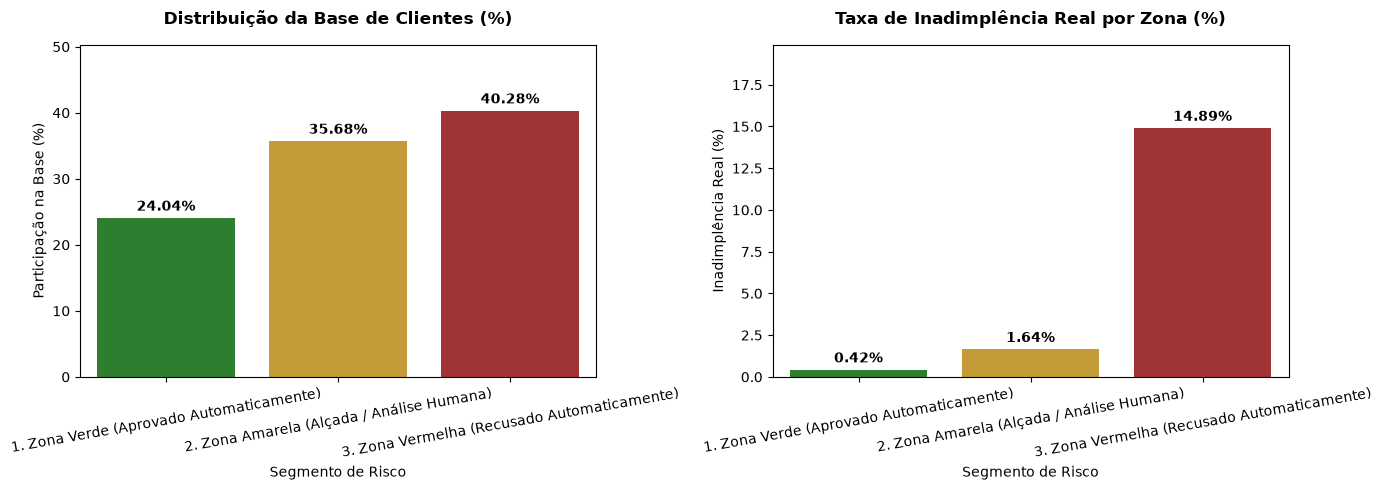

In [18]:
## Simulação de Política de Crédito e Faixas de Risco

# 1. Criando um DataFrame auxiliar com as probabilidades do modelo campeão (XGBoost)
df_simulacao = pd.DataFrame({
    'y_true': y_test,
    'proba_default': y_pred_proba_xgb
})

# 2. Definindo a função de política de crédito com base em cut-offs de probabilidade
def aplicar_politica_credito(proba):
    if proba < 0.10:
        return '1. Zona Verde (Aprovado Automaticamente)'
    elif proba < 0.30:
        return '2. Zona Amarela (Alçada / Análise Humana)'
    else:
        return '3. Zona Vermelha (Recusado Automaticamente)'

# Aplicando a política na base de teste
df_simulacao['Segmento_Risco'] = df_simulacao['proba_default'].apply(aplicar_politica_credito)

# 3. Calculando métricas de negócio por zona de risco
resumo_politica = df_simulacao.groupby('Segmento_Risco').agg(
    Volume_Clientes=('y_true', 'count'),
    Taxa_Inadimplencia_Real=('y_true', 'mean')
).reset_index()

# Formatando as porcentagens para apresentação executiva
resumo_politica['Porcentagem_Base (%)'] = ((resumo_politica['Volume_Clientes'] / len(df_simulacao)) * 100).round(2)
resumo_politica['Taxa_Inadimplencia_Real (%)'] = (resumo_politica['Taxa_Inadimplencia_Real'] * 100).round(2)

# Reordenando e limpando colunas
resumo_politica = resumo_politica[['Segmento_Risco', 'Volume_Clientes', 'Porcentagem_Base (%)', 'Taxa_Inadimplencia_Real (%)']]

print("Relatório Executivo: Simulação de Política de Crédito por Cut-offs")
display(resumo_politica)

# 4. # Gráfico Executivo: Distribuição da Base e Taxa de Inadimplência por Zona de Risco
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Definindo cores institucionais/intuitivas para as zonas (Verde, Amarelo/Dourado, Vermelho)
cores_zonas = ['forestgreen', 'goldenrod', 'firebrick']

# Subplot 1: Porcentagem da Base por Zona de Risco
sns.barplot(
    data=resumo_politica,
    x='Segmento_Risco',
    y='Porcentagem_Base (%)',
    palette=cores_zonas,
    ax=axes[0]
)
axes[0].set_title('Distribuição da Base de Clientes (%)', fontsize=12, fontweight='bold', pad=15)
axes[0].set_xlabel('Segmento de Risco', fontsize=10)
axes[0].set_ylabel('Participação na Base (%)', fontsize=10)
axes[0].tick_params(axis='x', rotation=10)

# Adicionando os valores exatos nas barras do Subplot 1
for p in axes[0].patches:
    height = p.get_height()
    axes[0].annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold', color='black',
                xytext=(0, 3), textcoords='offset points')
axes[0].set_ylim(0, max(resumo_politica['Porcentagem_Base (%)']) + 10)

# Subplot 2: Taxa de Inadimplência Real por Zona de Risco
sns.barplot(
    data=resumo_politica,
    x='Segmento_Risco',
    y='Taxa_Inadimplencia_Real (%)',
    palette=cores_zonas,
    ax=axes[1]
)
axes[1].set_title('Taxa de Inadimplência Real por Zona (%)', fontsize=12, fontweight='bold', pad=15)
axes[1].set_xlabel('Segmento de Risco', fontsize=10)
axes[1].set_ylabel('Inadimplência Real (%)', fontsize=10)
axes[1].tick_params(axis='x', rotation=10)

# Adicionando os valores exatos nas barras do Subplot 2
for p in axes[1].patches:
    height = p.get_height()
    axes[1].annotate(f'{height:.2f}%',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold', color='black',
                xytext=(0, 3), textcoords='offset points')
axes[1].set_ylim(0, max(resumo_politica['Taxa_Inadimplencia_Real (%)']) + 5)

plt.tight_layout()
plt.show()

#### Conclusão Políticas de Crédito e Cut-offs:

1. **Separação de Risco:** A política de *cut-offs* provou ser extremamente eficaz. A **Zona Verde** apresenta uma inadimplência residual de apenas **0,42%**, permitindo aprovação digital instantânea e segura. 
2. **Equilíbrio na Zona Amarela (1,64%):** A faixa intermediária (35,68% da base) captura clientes de risco moderado, ideais para alçada de crédito humana ou precificação baseada em risco (*risk-based pricing*).
3. **Blindagem de Capital na Zona Vermelha (14,89%):** O modelo barrou preventivamente os tomadores com alto risco de calote, protegendo a rentabilidade e a solvência da instituição financeira. 

### Etapa 6: Interpretabilidade do Modelo Campeão (XGBoost) - Feature Importance

**Lógica de Negócio e Transparência:** Em risco de crédito e em comitês regulatórios, não basta que o modelo acerte; é fundamental saber *por que* ele tomou uma decisão. A Análise de **Feature Importance** permite extrair quais variáveis o XGBoost mais utilizou para calcular a probabilidade de inadimplência, garantindo interpretabilidade e validação das regras de negócio.

Top 10 Variáveis Mais Importantes para o XGBoost:


,Feature,Importancia
12,Total_Delays,0.620841
0,RevolvingUtilizationOfUnsecuredLines,0.093514
14,Utilization_Bin_Baixa (0-30%),0.037780
7,NumberRealEstateLoansOrLines,0.031528
6,NumberOfTimes90DaysLate,0.031318
10,MonthlyIncome_is_missing,0.028053
2,NumberOfTime30-59DaysPastDueNotWorse,0.023544
17,Utilization_Bin_Estourado (>100%),0.020643
5,NumberOfOpenCreditLinesAndLoans,0.019432
1,age,0.016314


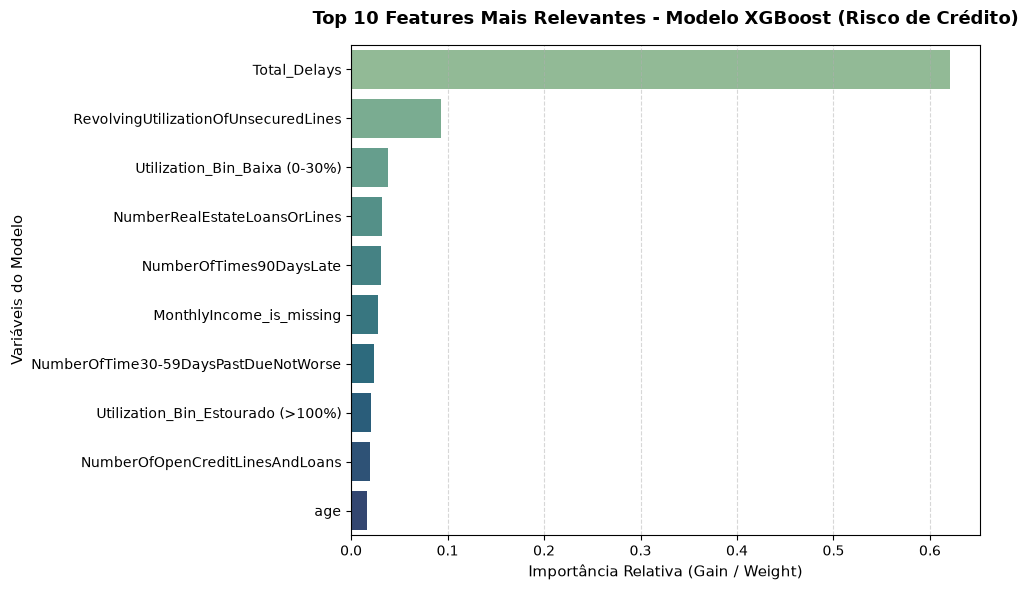

In [21]:
# 1. Extraindo a importância das features do modelo XGBoost treinado
importance_features = pd.DataFrame({
    'Feature': X_train.columns,
    'Importancia': xgb_model.feature_importances_
}).sort_values(by='Importancia', ascending=False)

# Exibindo o Top 10 em tabela
print("Top 10 Variáveis Mais Importantes para o XGBoost:")
display(importance_features.head(10))

# 2. Plotando o Gráfico de Importância das Features
plt.figure(figsize=(10, 6))
sns.barplot(
    data=importance_features.head(10),
    x='Importancia',
    y='Feature',
    palette='crest'
)

plt.title('Top 10 Features Mais Relevantes - Modelo XGBoost (Risco de Crédito)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Importância Relativa (Gain / Weight)', fontsize=11)
plt.ylabel('Variáveis do Modelo', fontsize=11)
plt.grid(True, axis='x', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

#### Conclusão da Interpretabilidade e Importância das Features:

1. **A Supremacia do Histórico de Atrasos (`Total_Delays`):** A variável criada na etapa de engenharia de recursos disparou na liderança isolada com mais de **62% de relevância**, comprovando que o comportamento histórico de reincidência de atrasos é o maior indicador de risco de um tomador de crédito.
2. **Validação das Faixas de Utilização (`Utilization_Bin`):** A presença destacada das faixas de utilização no ranking valida a importância das transformações que realizamos, mostrando que o uso do limite de crédito tem forte peso na predição do calote. 
3. **Alinhamento com o Mercado:** O ranking demonstra que o XGBoost aprendeu os pilares fundamentais do crédito (comportamento passado + comprometimento do limite atual).

### Etapa 7: Salvamento do Modelo XGBoost (Serialização)

**A Lógica do MLOps:** Após treinar, validar e interpretar o modelo campeão (*XGBoost*), o último passo do pipeline é **serializar o artefato**. Salvando o modelo em disco garantindo que ele possa ser carregado rapidamente para realizar predições em tempo real (como em uma API de concessão de crédito), sem a necessidade de reexecutar todo o treinamento.

In [22]:
import os
import joblib

# 1. Garantindo que o diretório de modelos existe
os.makedirs("../models", exist_ok=True)

# 2. Definindo o caminho de salvamento do XGBoost
caminho_modelo = "../models/xgb_credit_scoring_model.pkl"

# 3. Salvando o modelo treinado em disco
joblib.dump(xgb_model, caminho_modelo)
print(f"Modelo XGBoost salvo com sucesso em: {caminho_modelo}")

# Salvando o pipeline da Regressão Logística 
caminho_baseline = "../models/lr_baseline_model.pkl"
joblib.dump(pipeline_lr, caminho_baseline)
print(f"Modelo Baseline (Regressão Logística) salvo em: {caminho_baseline}")

Modelo XGBoost salvo com sucesso em: ../models/xgb_credit_scoring_model.pkl
Modelo Baseline (Regressão Logística) salvo em: ../models/lr_baseline_model.pkl
